In [1]:
import xarray as xr
import numpy as np
import os
from datetime import datetime
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import cartopy.crs as ccrs
import matplotlib.patches as patches

In [2]:
seasons = ["DJF", "MAM", "JJA", "SON"]
proj=ccrs.PlateCarree()

In [3]:
def seasonal_mean(list_of_months, season):
    '''
    list of months - list of months in string form to put into the file name
    season - index of seasons[] to expand the dimension

    Returns
    xr dataset with mean
    '''
    
    for i in range(len(list_of_months)):
        file = '/Users/anniefeng/data/processed_data/AIRS.' + list_of_months[i] + '.MonthlyMean.PBLH.nc4'
        curr_data = xr.open_dataset(file)
        curr_data = curr_data.expand_dims(season = [seasons[season]])

        if i == 0:
            test = curr_data

        else:
            test = xr.concat([curr_data, test], dim = 'season') 

    test_mean = test.mean(dim = 'season', skipna = True)
    
    to_return = test_mean.expand_dims(season = [seasons[season]])
    
    return to_return

def lonc(orig_lon):
    return ( (( orig_lon + 180 ) % 360 ) - 180 )

In [4]:
( (( 270 - 180 ) % 360 ) - 180 )

-90

# ERA5 Data

In [5]:
# load era5 data
ds = xr.open_mfdataset(
    "/Users/anniefeng/data/daily/20[0-9][0-9]/*.nc", combine='nested', concat_dim="time"
)

### Original Data

In [6]:
era5_data = ds.pblh

for i in range(4):
    test_mean = era5_data.sel(time = era5_data["time.season"] == seasons[i]).mean(dim = "time", skipna = True)
    season_data = test_mean.expand_dims(season = [seasons[i]])

    if i == 0:
        era5_seasonal = season_data

    else:
        era5_seasonal = xr.concat([era5_seasonal, season_data], dim = "season")

era5_seasonal

<xarray.DataArray 'pblh' (season: 4, lat: 400, lon: 1800)> Size: 23MB
dask.array<concatenate, shape=(4, 400, 1800), dtype=float64, chunksize=(1, 145, 900), chunktype=numpy.ndarray>
Coordinates:
  * season   (season) object 32B 'DJF' 'MAM' 'JJA' 'SON'
  * lat      (lat) float64 3kB -39.9 -39.7 -39.5 -39.3 ... 39.3 39.5 39.7 39.9
  * lon      (lon) float64 14kB 0.1 0.3 0.5 0.7 0.9 ... 359.3 359.5 359.7 359.9

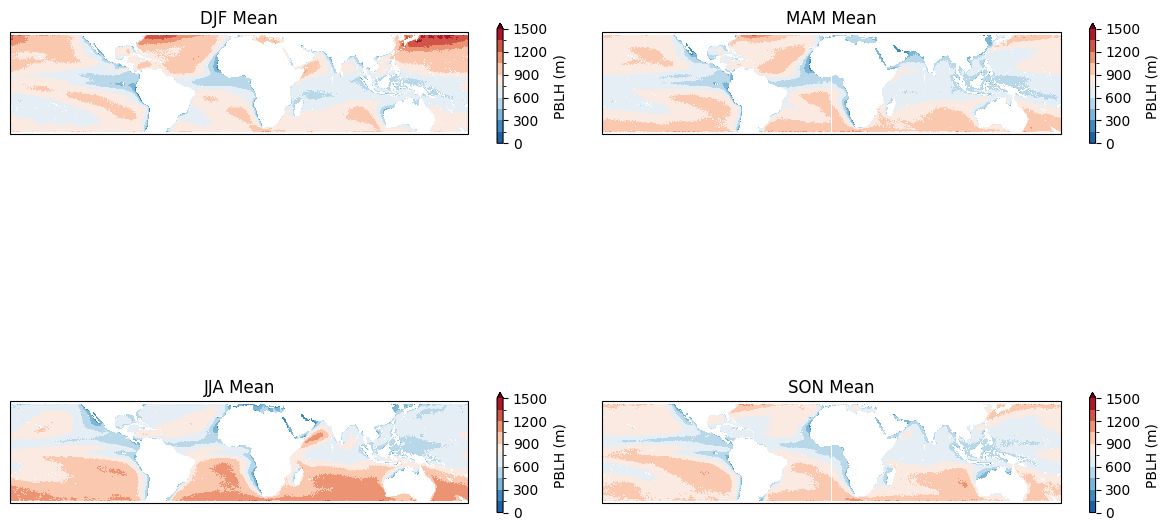

In [7]:
# plotting seasonal mean
fig = plt.figure(figsize=(12, 10))
proj=ccrs.PlateCarree()

# [0, 250, 500, 750, 1000, 1250, 1500, 1750, 2000, 2250, 2500, 2750, 3000]
bounds = np.linspace(0,1500,11)

# mpl.cm.viridis
cmap = mpl.cm.RdBu_r
norm = mpl.colors.BoundaryNorm(bounds, cmap.N, extend='both')

for i in range(len(seasons)):
        
    ax = plt.subplot(2 , 2, i+1, projection = proj)
    to_plot = era5_seasonal.sel(season = seasons[i])
    to_plot.plot(ax = ax, transform = proj, cmap = cmap, norm = norm,
                cbar_kwargs={'shrink': 0.2, 'label': "PBLH (m)"})

    ax.set_title(seasons[i] + " Mean")

plt.tight_layout();

In [8]:
era5_total = era5_seasonal.mean(dim = "season", skipna = True)
era5_total

<xarray.DataArray 'pblh' (lat: 400, lon: 1800)> Size: 6MB
dask.array<mean_agg-aggregate, shape=(400, 1800), dtype=float64, chunksize=(145, 900), chunktype=numpy.ndarray>
Coordinates:
  * lat      (lat) float64 3kB -39.9 -39.7 -39.5 -39.3 ... 39.3 39.5 39.7 39.9
  * lon      (lon) float64 14kB 0.1 0.3 0.5 0.7 0.9 ... 359.3 359.5 359.7 359.9

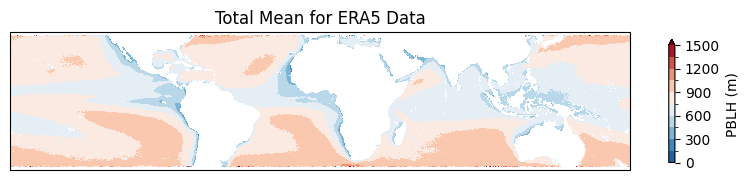

In [9]:
# total mean
fig, ax = plt.subplots(figsize = (10,8), subplot_kw=dict(projection=ccrs.PlateCarree()))

era5_total.plot(transform = ccrs.PlateCarree(), 
                ax = ax, cmap = cmap, norm = norm,
                cbar_kwargs={'shrink': 0.2, 'label': "PBLH (m)"})
ax.set_title("Total Mean for ERA5 Data");

In [10]:
test = era5_total.values.reshape(400*1800)

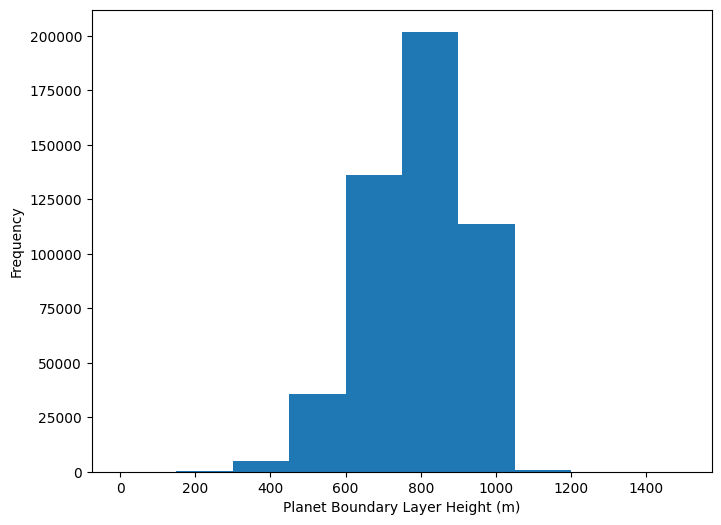

In [11]:
fig, ax = plt.subplots(figsize = (8,6))

ax.hist(test, bins = bounds)
ax.set_xlabel("Planet Boundary Layer Height (m)")
ax.set_ylabel("Frequency");

### Interpolated Data (1 by 1 grid)

In [12]:
era5_itp = ds.pblh.coarsen(lat = 5, lon = 5).mean()

In [13]:
era5_itp

<xarray.DataArray 'pblh' (time: 1766, lat: 80, lon: 360)> Size: 407MB
dask.array<mean_agg-aggregate, shape=(1766, 80, 360), dtype=float64, chunksize=(1, 29, 180), chunktype=numpy.ndarray>
Coordinates:
  * lat      (lat) float64 640B -39.5 -38.5 -37.5 -36.5 ... 36.5 37.5 38.5 39.5
  * lon      (lon) float64 3kB 0.5 1.5 2.5 3.5 4.5 ... 356.5 357.5 358.5 359.5
  * time     (time) datetime64[ns] 14kB 2019-01-01T12:00:00 ... 2023-11-01T12...
Attributes:
    long_name:  era5 pbl height
    units:      m

In [14]:
for i in range(4):
    test_mean = era5_itp.sel(time = era5_data["time.season"] == seasons[i]).mean(dim = "time", skipna = True)
    season_data = test_mean.expand_dims(season = [seasons[i]])

    if i == 0:
        era5_itp_seasonal = season_data

    else:
        era5_itp_seasonal = xr.concat([era5_itp_seasonal, season_data], dim = "season")

era5_itp_seasonal

<xarray.DataArray 'pblh' (season: 4, lat: 80, lon: 360)> Size: 922kB
dask.array<concatenate, shape=(4, 80, 360), dtype=float64, chunksize=(1, 29, 180), chunktype=numpy.ndarray>
Coordinates:
  * season   (season) object 32B 'DJF' 'MAM' 'JJA' 'SON'
  * lat      (lat) float64 640B -39.5 -38.5 -37.5 -36.5 ... 36.5 37.5 38.5 39.5
  * lon      (lon) float64 3kB 0.5 1.5 2.5 3.5 4.5 ... 356.5 357.5 358.5 359.5

In [15]:
era5_itp_total = era5_itp_seasonal.mean(dim = "season", skipna = True)
era5_itp_total

<xarray.DataArray 'pblh' (lat: 80, lon: 360)> Size: 230kB
dask.array<mean_agg-aggregate, shape=(80, 360), dtype=float64, chunksize=(29, 180), chunktype=numpy.ndarray>
Coordinates:
  * lat      (lat) float64 640B -39.5 -38.5 -37.5 -36.5 ... 36.5 37.5 38.5 39.5
  * lon      (lon) float64 3kB 0.5 1.5 2.5 3.5 4.5 ... 356.5 357.5 358.5 359.5

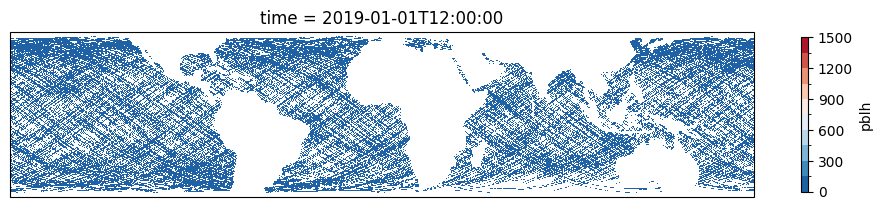

In [16]:
fig, ax = plt.subplots(figsize = (12,10), subplot_kw=dict(projection=ccrs.PlateCarree()))

(ds.pblh.sel(time = '2019-01-01T12:00:00')/1000).plot(transform = ccrs.PlateCarree(), 
                    ax = ax, cmap = cmap, norm = norm,
                    cbar_kwargs={'shrink': 0.2})

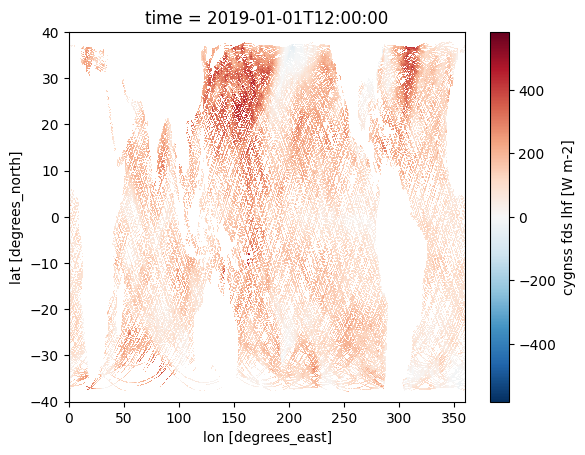

In [17]:
ds.lhf.sel(time = "2019-01-01T12:00:00").plot()

# GPS Data

In [3]:
# load and process gps data
gps_data = xr.open_dataset("/Users/anniefeng/data/pblh_gps_2006-2019_2x2_season.nc")
gps_data = gps_data.assign_coords(season=["DJF", "MAM", "JJA", "SON"])
gps_data = gps_data.atmosphere_boundary_layer_thickness.where(gps_data["surface_type"] == 0)

In [4]:
gps_total = gps_data.mean(dim = "season", skipna = True)

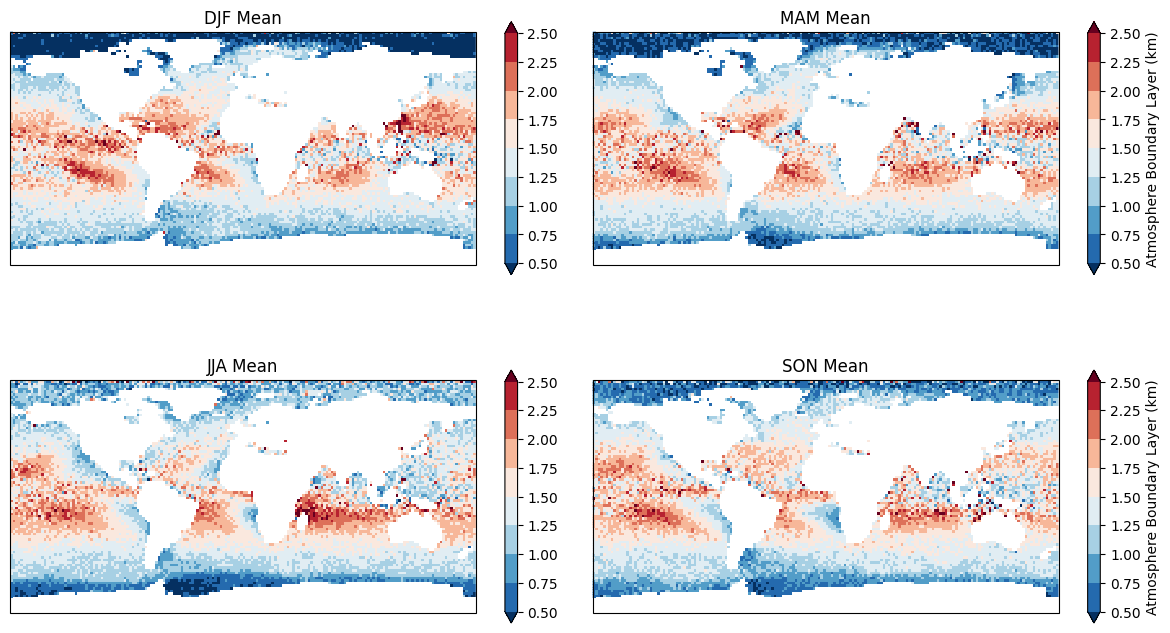

In [5]:
# plotting seasonal mean
fig = plt.figure(figsize=(12, 8))
proj=ccrs.PlateCarree()

# [0, 250, 500, 750, 1000, 1250, 1500, 1750, 2000, 2250, 2500, 2750, 3000]
bounds = [0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0, 2.25, 2.5]

# mpl.cm.viridis
cmap = mpl.cm.RdBu_r
norm = mpl.colors.BoundaryNorm(bounds, cmap.N, extend='both')


for i in range(len(seasons)):
    
    if i%2 == 1:
        cbar_kwarg = {'shrink': 0.6, 'label': "Atmosphere Boundary Layer (km)"}

    else:
        cbar_kwarg = {'shrink': 0.6, 'label' : ''}
    
    ax = plt.subplot(2 , 2, i+1, projection = proj)
    to_plot = gps_data.sel(season = seasons[i])/1000
    to_plot.plot(ax = ax, transform = proj, cmap = cmap, norm = norm,
                cbar_kwargs=cbar_kwarg)

    ax.set_title(seasons[i] + " Mean")

# data.sel(time = data["time.season"] == "DJF")
plt.tight_layout()

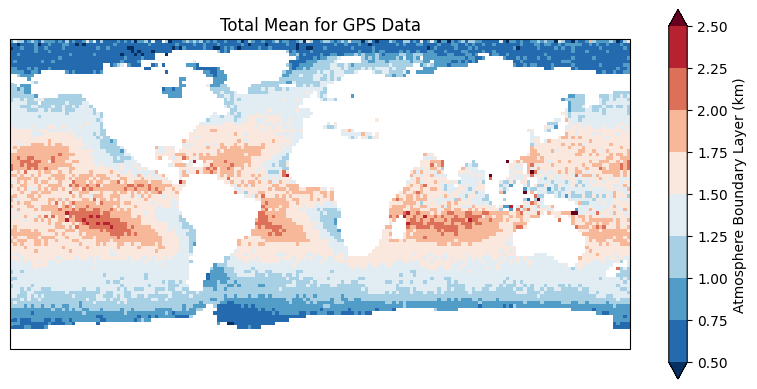

In [6]:
# total mean
fig, ax = plt.subplots(figsize = (10,8), subplot_kw=dict(projection=ccrs.PlateCarree()))

gps_total_mean = gps_total/1000
gps_total_mean.plot(transform = ccrs.PlateCarree(), 
                    ax = ax, cmap = cmap, norm = norm,
                    cbar_kwargs={'shrink': 0.6, 'label': "Atmosphere Boundary Layer (km)"})
ax.set_title("Total Mean for GPS Data");

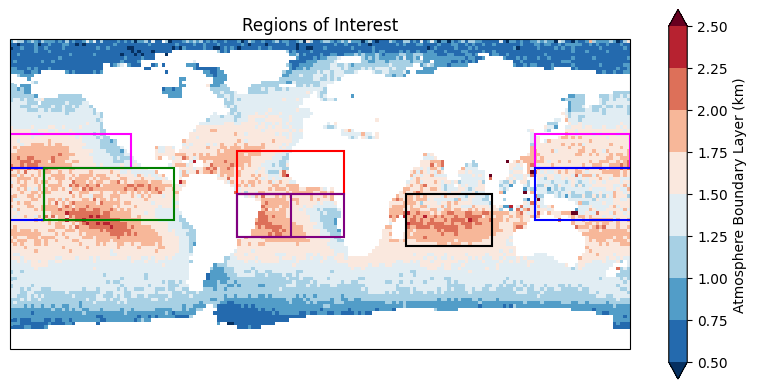

In [8]:
fig, ax = plt.subplots(figsize = (10,8), subplot_kw=dict(projection=ccrs.PlateCarree()))
gps_total_mean = gps_data.mean(dim = "season")/1000
gps_total_mean.plot(transform = ccrs.PlateCarree(), 
                    ax = ax, cmap = cmap, norm = norm,
                    cbar_kwargs={'shrink': 0.6, 'label': "Atmosphere Boundary Layer (km)"})
ax.set_title("Regions of Interest");

# indian ocean
ax.add_patch(patches.Rectangle((50, -30), 100 - 50, -20 - (-50),
                              linewidth=1.5, edgecolor='black', facecolor='none'))

# # above pacific ocean
ax.add_patch(patches.Rectangle((125, 15), 180-125, 20,
                               linewidth=1.5, edgecolor='magenta', facecolor='none'))
ax.add_patch(patches.Rectangle((-180, 15), 70, 20,
                               linewidth=1.5, edgecolor='magenta', facecolor='none'))

# west pacific ocean
ax.add_patch(patches.Rectangle((125, -15), 200-125, 15 - (-15),
                              linewidth=1.5, edgecolor='blue', facecolor='none'))
ax.add_patch(patches.Rectangle((-180, -15), 20, 15 - (-15),
                              linewidth=1.5, edgecolor='blue', facecolor='none'))

# east pacific ocean
ax.add_patch(patches.Rectangle((-160, -15), 275 - 200, 15 - (-15),
                              linewidth=1.5, edgecolor='green', facecolor='none'))

# north atlantic ocean
ax.add_patch(patches.Rectangle((-48, 0), 62, 25,
                              linewidth=1.5, edgecolor='red', facecolor='none'))

# south atlantic ocean
ax.add_patch(patches.Rectangle((-48, -25), 62, 25,
                              linewidth=1.5, edgecolor='purple', facecolor='none'))

# south atlantic ocean
ax.add_patch(patches.Rectangle((-48, -25), 31, 25,
                              linewidth=1.5, edgecolor='purple', facecolor='none'));

In [23]:
gps_data

<xarray.DataArray 'atmosphere_boundary_layer_thickness' (season: 4, lat: 90,
                                                         lon: 180)> Size: 259kB
array([[[  nan,   nan,   nan, ...,   nan,   nan,   nan],
        [  nan,   nan,   nan, ...,   nan,   nan,   nan],
        [  nan,   nan,   nan, ...,   nan,   nan,   nan],
        ...,
        [ 611.,  511.,  380., ...,  391.,  571.,  539.],
        [ 330.,  320.,  320., ...,  500.,  460.,  270.],
        [ 459.,  140.,  460., ...,  300.,  189.,  619.]],

       [[  nan,   nan,   nan, ...,   nan,   nan,   nan],
        [  nan,   nan,   nan, ...,   nan,   nan,   nan],
        [  nan,   nan,   nan, ...,   nan,   nan,   nan],
        ...,
        [ 460.,  550.,  509., ...,  391.,  500.,  560.],
        [ 390.,  410.,  720., ...,  510.,  481.,  480.],
        [ 389.,  980.,  660., ..., 2389.,  429.,  309.]],

       [[  nan,   nan,   nan, ...,   nan,   nan,   nan],
        [  nan,   nan,   nan, ...,   nan,   nan,   nan],
        [  nan,   nan,   nan, ...,   nan,   nan,   nan],
        ...,
        [ 650., 1331.,  610., ...,  511., 1040.,  550.],
        [1130., 1010., 1290., ..., 1140.,  850.,  790.],
        [ 699., 2360., 2680., ..., 1270., 1910.,  469.]],

       [[  nan,   nan,   nan, ...,   nan,   nan,   nan],
        [  nan,   nan,   nan, ...,   nan,   nan,   nan],
        [  nan,   nan,   nan, ...,   nan,   nan,   nan],
        ...,
        [ 351.,  760.,  980., ...,  440.,  790.,  720.],
        [ 520.,  840.,  270., ...,  400.,  470.,  660.],
        [2039.,  550.,  980., ...,  299.,  239.,  629.]]],
      shape=(4, 90, 180), dtype=float32)
Coordinates:
  * lat      (lat) float32 360B -89.0 -87.0 -85.0 -83.0 ... 83.0 85.0 87.0 89.0
  * lon      (lon) float32 720B 1.0 3.0 5.0 7.0 9.0 ... 353.0 355.0 357.0 359.0
  * season   (season) <U3 48B 'DJF' 'MAM' 'JJA' 'SON'
Attributes:
    units:      meters
    long_name:  atmosphere boundary layer thickness mean value

# AIRS Data

In [40]:
djf = ["12", "01", "02"]
mam = ["03", "04", "05"]
jja = ["06", "07", "08"]
son = ["09", "10", "11"]

djf_mean = seasonal_mean(djf, 0)
mam_mean = seasonal_mean(mam, 1)
jja_mean = seasonal_mean(jja, 2)
son_mean = seasonal_mean(son, 3)

airs_data = xr.concat([djf_mean, mam_mean, jja_mean, son_mean], dim = 'season')
airs_data = airs_data.rename({'Latitude' : 'lat', 'Longitude':'lon'})
airs_data = airs_data.bndry_lyr_top_ADAverageMeter

In [25]:
airs_total = airs_data.mean(dim = "season", skipna = True)

In [42]:
airs_data

<xarray.DataArray 'bndry_lyr_top_ADAverageMeter' (season: 4, lat: 180, lon: 360)> Size: 2MB
array([[[          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
         2742.71485234,           nan,           nan],
        ...,
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan]],

       [[          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
...
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan]],

       [[          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        ...,
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan]]],
      shape=(4, 180, 360))
Coordinates:
  * season   (season) object 32B 'DJF' 'MAM' 'JJA' 'SON'
  * lat      (lat) float64 1kB 90.0 89.0 88.0 87.0 ... -86.0 -87.0 -88.0 -89.0
  * lon      (lon) float64 3kB -180.0 -179.0 -178.0 -177.0 ... 177.0 178.0 179.0

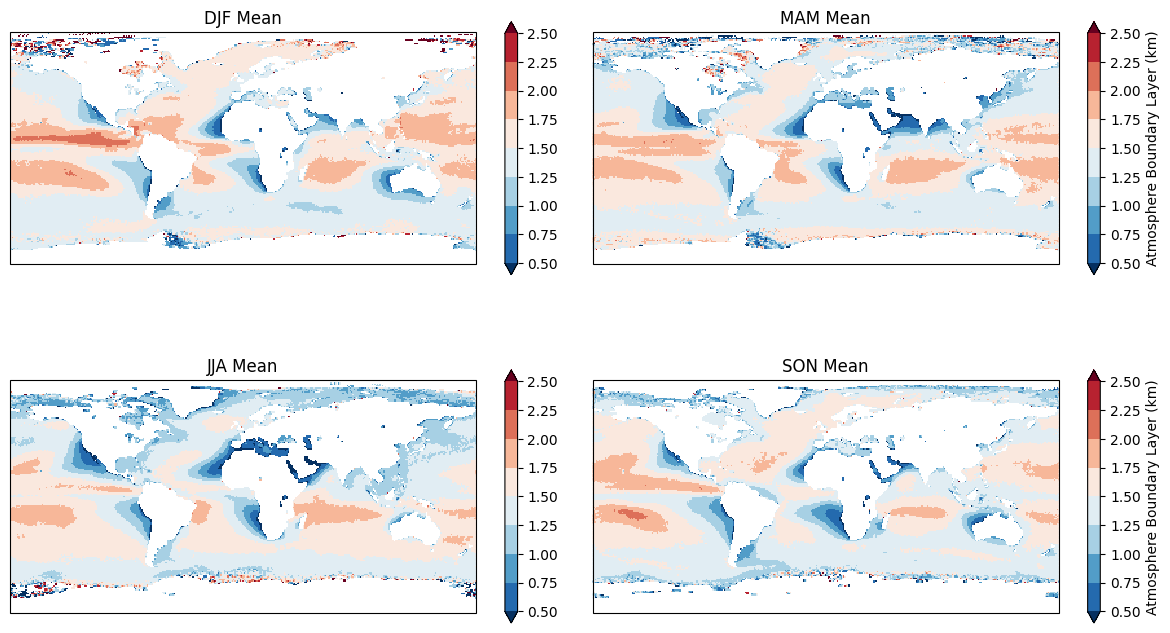

In [27]:
fig = plt.figure(figsize=(12, 8))
proj=ccrs.PlateCarree()

# [0, 250, 500, 750, 1000, 1250, 1500, 1750, 2000, 2250, 2500, 2750, 3000]
bounds = [0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0, 2.25, 2.5]

# mpl.cm.viridis
cmap = mpl.cm.RdBu_r
norm = mpl.colors.BoundaryNorm(bounds, cmap.N, extend='both')

for i in range(len(seasons)):
    
    if i%2 == 1:
        cbar_kwarg = {'shrink': 0.6, 'label': "Atmosphere Boundary Layer (km)"}

    else:
        cbar_kwarg = {'shrink': 0.6, 'label' : ''}
    
    ax = plt.subplot(2 , 2, i+1, projection = proj)
    to_plot = airs_data.sel(season = seasons[i])/1000
    to_plot.plot(ax = ax, transform = proj, cmap = cmap, norm = norm,
                cbar_kwargs=cbar_kwarg)

    ax.set_title(seasons[i] + " Mean")

plt.tight_layout()

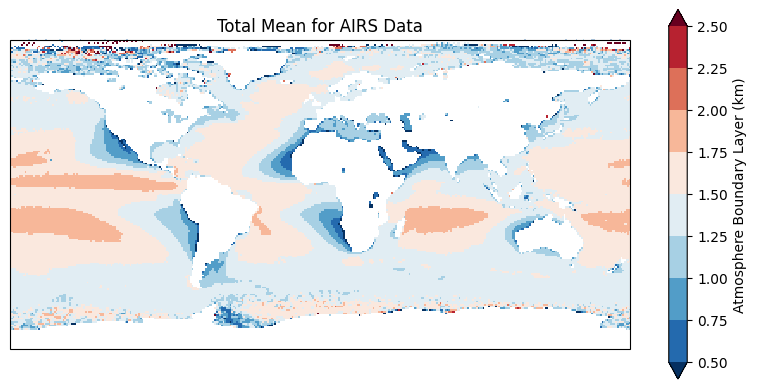

In [28]:
fig, ax = plt.subplots(figsize = (10,8), subplot_kw=dict(projection=ccrs.PlateCarree()))

airs_total_mean = airs_total/1000
airs_total_mean.plot(transform = ccrs.PlateCarree(), 
                    ax = ax, cmap = cmap, norm = norm,
                    cbar_kwargs={'shrink': 0.6, 'label': "Atmosphere Boundary Layer (km)"})
ax.set_title("Total Mean for AIRS Data");

# Comparing PBLH :p

ERA5 Data

- regular
    - seasonal: era5_seasonal
    - total: era5_total
- interpolated
    - seasonal: era5_itp_seasonal
    - total: era5_itp_total

AIRS Data

- seasonal: airs_data
- total: airs_total

GPS Data

- seasonal: gps_data
- total: gps_total

In [43]:
def regional_mean(lats, lons, data_seasonal, data_total, lons_double, airs):
    '''
    Selects a region based on lats and lons range provided and calculates, for each data set
    (airs, gps, era5, era5_itp), the means of DJF, JJA, and total mean

    Returns 1 list of length 3 with the above means

    Parameters
    ---------------
    lats - latitude range
    lons - longitude range
    data_seasonal - xarray dataset with season coordinate
    data_total - xarray dataset with total mean over time
    '''

    if airs == True:
        it = 0

    else:
        it = 1
    
    temp = data_seasonal.sel(lat = lats, lon = lons[it])
    djf = float(temp.sel(season = "DJF").mean(skipna = True).values)
    jja = float(temp.sel(season = "JJA").mean(skipna = True).values)
    total = float(data_total.sel(lat = lats, lon = lons[it]).mean(skipna = True).values)
    
    temp_mean = np.array([djf, jja, total])

    if lons_double == True:
        # AIRS double coordinates
        temp_2 = data_seasonal.sel(lat = lats, lon = lons[2])
        djf_2 = float(temp.sel(season = "DJF").mean(skipna = True).values)
        jja_2 = float(temp.sel(season = "JJA").mean(skipna = True).values)
        total_2 = float(data_total.sel(lat = lats, lon = lons[2]).mean(skipna = True).values)

        temp_mean += np.array([djf_2, jja_2, total_2])

    elif lons_double == False:
        # ERA5, GPS double coordinates
        temp_2 = data_seasonal.sel(lat = lats, lon = lons[3])
        djf_2 = float(temp.sel(season = "DJF").mean(skipna = True).values)
        jja_2 = float(temp.sel(season = "JJA").mean(skipna = True).values)
        total_2 = float(data_total.sel(lat = lats, lon = lons[3]).mean(skipna = True).values)

        temp_mean += np.array([djf_2, jja_2, total_2])

    return temp_mean

In [44]:
def regional_std(lats, lons, data_seasonal, data_total, lons_double, airs):
    '''
    Selects a region based on lats and lons range provided and calculates, for each data set
    (airs, gps, era5, era5_itp), the standard deviations of DJF, JJA, and total mean

    Returns 1 list of length 3 with the above std

    Parameters
    ---------------
    lats - latitude range
    lons - longitude range
    data_seasonal - xarray dataset with season coordinate
    data_total - xarray dataset with total mean over time
    '''

    if airs == True:
        it = 0

    else:
        it = 1
    
    temp = data_seasonal.sel(lat = lats, lon = lons[it])
    djf = float(temp.sel(season = "DJF").std(skipna = True).values)
    jja = float(temp.sel(season = "JJA").std(skipna = True).values)
    total = float(data_total.sel(lat = lats, lon = lons[it]).std(skipna = True).values)
    
    temp_std = np.array([djf, jja, total])

    if lons_double == True:
        # AIRS double coordinates
        temp_2 = data_seasonal.sel(lat = lats, lon = lons[2])
        djf_2 = float(temp.sel(season = "DJF").std(skipna = True).values)
        jja_2 = float(temp.sel(season = "JJA").std(skipna = True).values)
        total_2 = float(data_total.sel(lat = lats, lon = lons[2]).std(skipna = True).values)

        temp_std += np.array([djf_2, jja_2, total_2])

    elif lons_double == False:
        # ERA5, GPS double coordinates
        temp_2 = data_seasonal.sel(lat = lats, lon = lons[3])
        djf_2 = float(temp.sel(season = "DJF").std(skipna = True).values)
        jja_2 = float(temp.sel(season = "JJA").std(skipna = True).values)
        total_2 = float(data_total.sel(lat = lats, lon = lons[3]).std(skipna = True).values)

        temp_std += np.array([djf_2, jja_2, total_2])

    return temp_std

### Indian Ocean

In [35]:
lats_use = slice(-15,15)
lons_use = slice(50,100)

In [36]:
era5_data

<xarray.DataArray 'pblh' (time: 1766, lat: 400, lon: 1800)> Size: 10GB
dask.array<concatenate, shape=(1766, 400, 1800), dtype=float64, chunksize=(1, 145, 900), chunktype=numpy.ndarray>
Coordinates:
  * lat      (lat) float64 3kB -39.9 -39.7 -39.5 -39.3 ... 39.3 39.5 39.7 39.9
  * lon      (lon) float64 14kB 0.1 0.3 0.5 0.7 0.9 ... 359.3 359.5 359.7 359.9
  * time     (time) datetime64[ns] 14kB 2019-01-01T12:00:00 ... 2023-11-01T12...
Attributes:
    long_name:  era5 pbl height
    units:      m

In [ ]:
x = np.arange(3)
# airs_mean = regional_mean(slice(15,-15), slice(-130,-80), airs_data, airs_total, )
# gps_mean = regional_mean(lats_use, lons_use, gps_data, gps_total)
# era5_mean = regional_mean(lats_use, lons_use, era5_seasonal, era5_total)
# era5_itp_mean = regional_mean(lats_use, lons_use, era5_itp_seasonal, era5_itp_total)

width = 0.2
c = [100, 300, 200]


# plot data in grouped manner of bar type
plt.bar(x-0.3, airs_mean, width, color='tab:red')
plt.errorbar(x-0.3, airs_mean, yerr=c, fmt="o", color="pink")

plt.bar(x-0.1, gps_mean, width, color='tab:blue')
plt.bar(x+0.1, era5_mean, width, color='tab:orange')
plt.bar(x+0.3, era5_itp_mean, width, color='tab:green')
plt.xticks(x, ['DJF', 'JJA', 'Total'])
plt.xlabel("Comparison between DJF, JJA, and Total Means")
plt.ylabel("Mean")
plt.legend(["AIRS", "GPS", "ERA5", "ERA5 Interpolated"],loc='center left', bbox_to_anchor=(1, 0.5))
plt.show()

In [ ]:
c = [1, 3, 2, 1]


# plot data in grouped manner of bar type
plt.bar(x-0.3, airs_mean, width, color='tab:red')
plt.errorbar(x-0.3, airs_mean, yerr=c, fmt="o", color="pink")

plt.bar(x-0.1, gps_mean, width, color='tab:blue')
plt.bar(x+0.1, era5_mean, width, color='tab:orange')
plt.bar(x+0.3, era5_itp_mean, width, color='tab:green')
plt.xticks(x, ['DJF', 'JJA', 'Total'])
plt.xlabel("Comparison between DJF, JJA, and Total Means")
plt.ylabel("Mean")
plt.legend(["AIRS", "GPS", "ERA5", "ERA5 Interpolated"],loc='center left', bbox_to_anchor=(1, 0.5))
plt.show()

In [ ]:
test = np.array(([1,2,3],[4,5,6], [7,8,9]))
test[2]

In [ ]:
airs_total

In [ ]:
airs_total

In [ ]:
subregions = ["Upper Pacific Ocean", "Western Pacific", "Eastern Pacific", 
              "Indian Ocean", "Northern Atlantic", "Southern Atlantic"]

In [ ]:
airs_total.sel(lon = slice(-160,-85)).plot()

In [ ]:
era5_itp_total.sel(lon = slice(200,275)).plot()

In [ ]:
lats_use = np.array(([slice(15,-15), slice(-15,15)],
                    [slice(35,15), slice(15,35)],
                    [slice(15,-15), slice(-15,15)],
                    [slice(15,-15), slice(-15,15)],
                    [slice(25,0), slice(0,25)],
                    [slice(0,-25), slice(-25,0)]))
lats_use[1][0]

In [48]:
era5_data

<xarray.DataArray 'pblh' (time: 1766, lat: 400, lon: 1800)> Size: 10GB
dask.array<concatenate, shape=(1766, 400, 1800), dtype=float64, chunksize=(1, 145, 900), chunktype=numpy.ndarray>
Coordinates:
  * lat      (lat) float64 3kB -39.9 -39.7 -39.5 -39.3 ... 39.3 39.5 39.7 39.9
  * lon      (lon) float64 14kB 0.1 0.3 0.5 0.7 0.9 ... 359.3 359.5 359.7 359.9
  * time     (time) datetime64[ns] 14kB 2019-01-01T12:00:00 ... 2023-11-01T12...
Attributes:
    long_name:  era5 pbl height
    units:      m

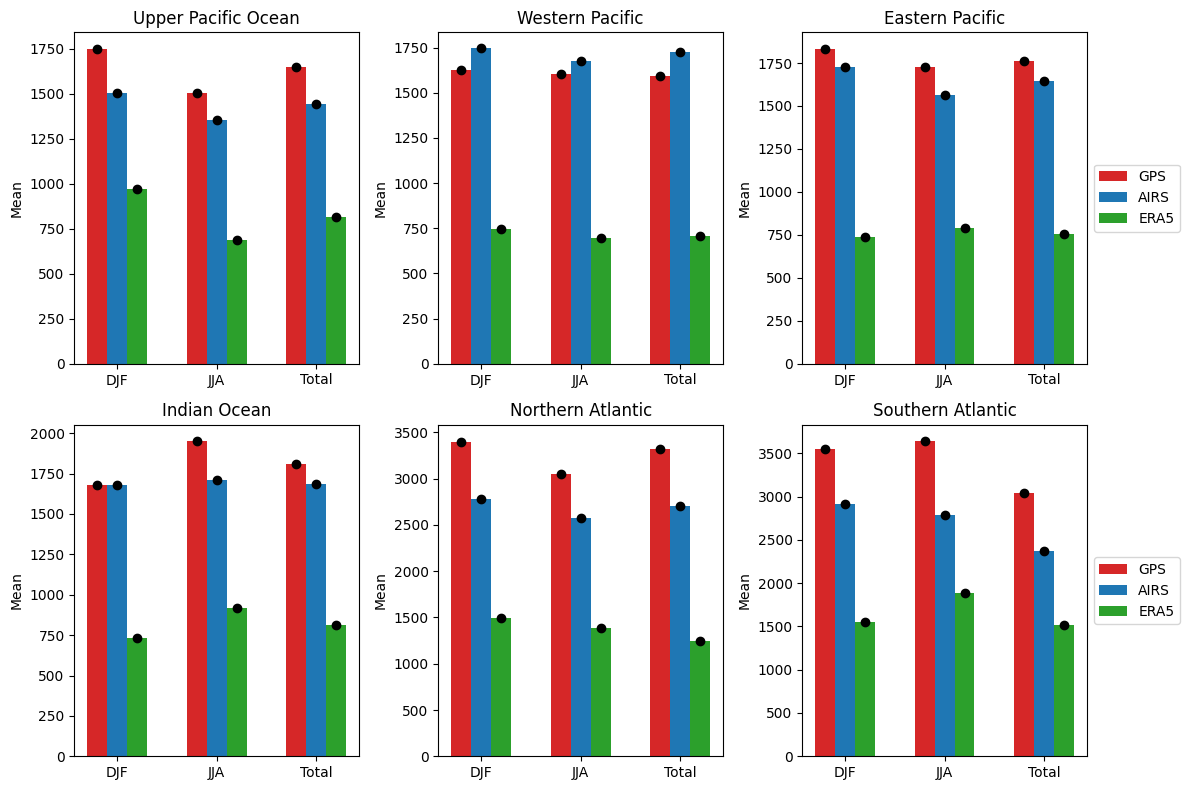

In [49]:
# plotting seasonal mean
fig = plt.figure(figsize=(12, 8))
x = np.arange(3)
width = 0.2

subregions = ["Upper Pacific Ocean", "Western Pacific", "Eastern Pacific", 
              "Indian Ocean", "Northern Atlantic", "Southern Atlantic"]

# airs first (goes backwards + -> -)
lats_use = np.array(([slice(35,15), slice(15,35)],
                    [slice(15,-15), slice(-15,15)],
                    [slice(15,-15), slice(-15,15)],
                    [slice(0,-30), slice(-30,0)],
                    [slice(25,0), slice(0,25)],
                    [slice(0,-25), slice(-25,0)]))

# airs first and third (goes from -180 to 180)
# era5, gps, second and fourth
lons_use = np.array(([slice(-180,-110), slice(125,250), slice(125,180), 0],
                    [slice(-180,-160), slice(125,200), slice(125,180), 0],
                    [slice(-160,-85), slice(200,275), 0, 0],
                    [slice(50,100), slice(50,100), 0, 0],
                    [slice(-48, 15), slice(312,360), 0, slice(0,15)],
                    [slice(-48, 15), slice(312,360), 0, slice(0,15)]))


for i in range(6):

    if i == 0 or i == 1:
        lons_double = True

    if i == 4 or i == 5:
        lons_double = False

    else:
        lons_double = None

    gps_mean = regional_mean(lats_use[i][1], lons_use[i], gps_data, gps_total, lons_double, airs = False)
    airs_mean = regional_mean(lats_use[i][0], lons_use[i], airs_data, airs_total, lons_double, airs = True)
    era5_mean = regional_mean(lats_use[i][1], lons_use[i], era5_seasonal, era5_total, lons_double, airs = False)
    # era5_itp_mean = regional_mean(lats_use[i][1], lons_use[i], era5_itp_seasonal, era5_itp_total, lons_double, airs = False)

    gps_std = 1.96*regional_std(lats_use[i][1], lons_use[i], gps_data, gps_total, lons_double, airs = False)/np.sqrt(90*180)
    airs_std = 1.96*regional_std(lats_use[i][0], lons_use[i], airs_data, airs_total, lons_double, airs = True)/np.sqrt(360*180)
    era5_std = 1.96*regional_std(lats_use[i][1], lons_use[i], era5_seasonal, era5_total, lons_double, airs = False)/np.sqrt(400*1800)
    # era5_itp_std = regional_std(lats_use[i][1], lons_use[i], era5_itp_seasonal, era5_itp_total, lons_double, airs = False)
    
    ax = plt.subplot(2 , 3, i+1)
    ax.bar(x-0.2, gps_mean, width, color='tab:red')
    ax.bar(x, airs_mean, width, color='tab:blue')
    ax.bar(x+0.2, era5_mean, width, color='tab:green')
    #ax.bar(x+0.3, era5_itp_mean, width, color='tab:green')

    ax.errorbar(x-0.2, gps_mean, yerr=gps_std, fmt="o", color="black")
    ax.errorbar(x, airs_mean, yerr=airs_std, fmt="o", color="black")
    ax.errorbar(x+0.2, era5_mean, yerr=era5_std, fmt="o", color="black")
    #ax.errorbar(x+0.3, era5_itp_mean, yerr=era5_itp_std, fmt="o", color="black")
    
    ax.set_xticks(x, ['DJF', 'JJA', 'Total'])
    ax.set_ylabel("Mean")

    if i%3 == 2:
        ax.legend(["GPS", "AIRS", "ERA5"],loc='center left', bbox_to_anchor=(1, 0.5))

    ax.set_title(subregions[i])

plt.tight_layout()